In [30]:
# Requirements install
#%pip install numpy pandas matplotlib seaborn scikit-learn torch imbalanced-learn

# Imports
import seaborn, sklearn, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imblearn

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
import warnings

# Scikit-learn imports
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, KFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, recall_score, precision_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from scipy.stats import randint
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


warnings.filterwarnings("ignore", category=ConvergenceWarning)


Data loading and preprocessing, data doesn't contain missing feature values so not nessasary to do removal for missing values

In [31]:
# Set a random seed for reproducibility
random_seed = 42
torch.manual_seed(random_seed)
np.random.seed(random_seed)
random.seed(random_seed)

# load the data
spambase_filepath = './data/spambase.data'
data = pd.read_csv(spambase_filepath, header=None)

X = data.iloc[: , :-1] # all rows, all columns except for the label
y = data.iloc[:, -1] # all rows, last column

n_rows, n_features = X.shape # store the number of rows and features

print(f"Number of rows: {n_rows}")
print(f"Number of features: {n_features}")
print(f"Number of spam (1): {y.value_counts()[1]}, not spam (0): {y.value_counts()[0]}")

#arrange into train and test splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed)

#scale using standard scaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#define x and y tensors
X_train_t = torch.Tensor(X_train)
X_test_t = torch.Tensor(X_test)
y_train_t = torch.Tensor(y_train.to_numpy()).view(-1, 1)
y_test_t = torch.Tensor(y_test.to_numpy()).view(-1, 1) 

Number of rows: 4601
Number of features: 57
Number of spam (1): 1813, not spam (0): 2788


Calculation for majority vote baseline

In [32]:
majority_class = y.value_counts().idxmax()
baseline_accuracy = (y == majority_class).mean()

print(f"Baseline accuracy: {baseline_accuracy:.3f}")

Baseline accuracy: 0.606


Training using Logistic Regression

In [33]:
EPOCH_LR = 100 

def make_lr_model(config, *, for_epoch_training=False, max_iter=1000):
    params = {
        "solver": "saga",
        "random_state": random_seed,
        "penalty": config["penalty"],
        "C": config["C"],
        "max_iter": max_iter,
        "warm_start": False,
    }
    if config.get("l1_ratio") is not None:
        params["l1_ratio"] = config["l1_ratio"]
    if for_epoch_training:
        params["max_iter"] = 1
        params["warm_start"] = True
    return LogisticRegression(**params)

lr_search_space = [
    {"name": "L2_C1.0", "penalty": "l2", "C": 1.0},
    {"name": "L2_C0.2", "penalty": "l2", "C": 0.2},
    {"name": "L1_C0.5", "penalty": "l1", "C": 0.5},
    {"name": "ElasticNet_C0.8_l1_0.5", "penalty": "elasticnet", "C": 0.8, "l1_ratio": 0.5},
]

def train_logistic_regression(model, epoch_lr):
    train_loss, test_loss, test_acc, test_recall, test_precision, epochs = [], [], [], [], [], []

    for epoch in range(epoch_lr):

        model.fit(X_train, y_train)

        #Record loss and accuracy every 5 epoch
        if epoch%5 == 0:
            y_pred = model.predict_proba(X_train)[:, 1]
            y_pred_t = model.predict_proba(X_test)[:, 1]
            loss = log_loss(y_train, y_pred)
            loss_t = log_loss(y_test, y_pred_t)
            acc = model.score(X_test, y_test)
            recall = recall_score(y_test, (y_pred_t >= 0.5).astype(int))
            precision = precision_score(y_test, (y_pred_t >= 0.5).astype(int))

            train_loss.append(loss)
            test_loss.append(loss_t)   
            test_acc.append(acc)
            test_recall.append(recall)
            test_precision.append(precision)
            epochs.append(epoch) 

    return train_loss, test_loss, test_acc, test_recall, test_precision, epochs

best_run = None

for config in lr_search_space:
    model_lr = make_lr_model(config, for_epoch_training=True)
    history = train_logistic_regression(model_lr, EPOCH_LR)
    final_accuracy = history[2][-1]
    ratio_msg = f", l1_ratio={config['l1_ratio']}" if config.get('l1_ratio') is not None else ''
    print(f"{config['name']}: penalty={config['penalty']}, C={config['C']}{ratio_msg} -> Test Accuracy: {final_accuracy:.3f}")
    if not best_run or final_accuracy > best_run['final_accuracy']:
        best_run = {
            "config": config,
            "history": history,
            "final_accuracy": final_accuracy
        }

train_loss_lr, test_loss_lr, acc_lr, recall_lr, precision_lr, epoch_lr = best_run["history"]
best_lr_config = best_run["config"]
print(f"Selected logistic regression config: {best_lr_config['name']} (penalty={best_lr_config['penalty']}, C={best_lr_config['C']}) with test accuracy {best_run['final_accuracy']:.3f}")


L2_C1.0: penalty=l2, C=1.0 -> Test Accuracy: 0.902
L2_C0.2: penalty=l2, C=0.2 -> Test Accuracy: 0.899
L1_C0.5: penalty=l1, C=0.5 -> Test Accuracy: 0.902
ElasticNet_C0.8_l1_0.5: penalty=elasticnet, C=0.8, l1_ratio=0.5 -> Test Accuracy: 0.903
Selected logistic regression config: ElasticNet_C0.8_l1_0.5 (penalty=elasticnet, C=0.8) with test accuracy 0.903


Graph train and test loss, anc test accuracy

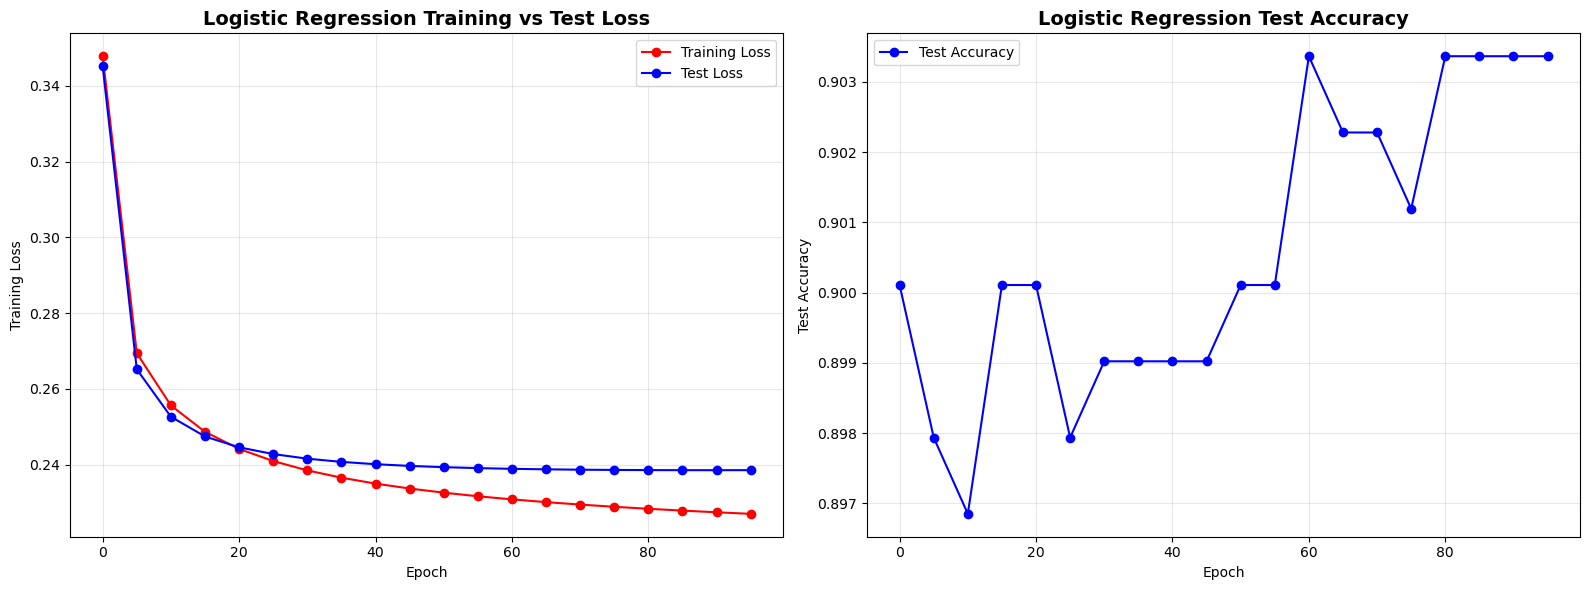

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epoch_lr, train_loss_lr, label='Training Loss', color='red', marker='o')
axes[0].plot(epoch_lr, test_loss_lr, label='Test Loss', color='blue', marker='o')
axes[0].set_title('Logistic Regression Training vs Test Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_lr, acc_lr, label='Test Accuracy', color='blue', marker='o')
axes[1].set_title('Logistic Regression Test Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training using Neural Network

In [35]:
#define some constants for neural network training
LR_NN = 0.005
EPOCH_NN = 150
WEIGHT_DECAY_NN = 1e-4
DROPOUT_P = 0.2

#define neural network class
class NeuralNetwork(nn.Module):
    def __init__(self, features, dropout):
        super().__init__()
        self.flatten = nn.Flatten()
        self.stack = nn.Sequential(
            nn.Linear(features, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16,1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.stack(x)
    
    
def train_neural_network(model, criterion, optimizer, epoch_nn, scheduler=None, X_train_t=X_train_t, y_train_t=y_train_t, X_test_t=X_test_t, y_test_t=y_test_t):
    train_loss, test_loss, test_acc, test_recall, test_precision, epochs = [], [], [], [], [], []

    model.train()
    #training loop
    for epoch in range(epoch_nn):
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)

        #compute gradients, update parameters
        loss.backward()
        optimizer.step()

        if scheduler is not None: #Learning rate would be None if no scheduler is used
            scheduler.step()

        if epoch%5 == 0:
            model.eval()

            with torch.no_grad():
                y_pred = model(X_test_t)
                y_pred_binary = (y_pred >= 0.5).int()
                acc = accuracy_score(y_test_t, y_pred_binary)
                recall = recall_score(y_test_t, y_pred_binary)
                precision = precision_score(y_test_t, y_pred_binary)
                loss_t = criterion(y_pred, y_test_t)

                train_loss.append(loss.item())
                test_loss.append(loss_t.item())
                test_acc.append(acc) 
                test_recall.append(recall)
                test_precision.append(precision)
                epochs.append(epoch)
            
            model.train()

    return train_loss, test_loss, test_acc, test_recall, test_precision, epochs

# hyperparameter tuning for neural network
def nn_hyperparameter_tuning(iter):

    best_wd = None
    best_dp = None
    best_gamma = None
    best_step = None
    best_acc = 0

    kf = KFold(n_splits=5, shuffle=True)

    for i in range(iter):
        wd = 10**random.uniform(-5, -3)
        dp = random.uniform(0.1, 0.5)
        gamma = random.uniform(0.1, 0.9)
        step = random.randint(10, 50)
        fold_acc = []

        for j, (train_index, val_index) in enumerate(kf.split(X_train_t)):
            X_train_fold, X_val_fold = X_train_t[train_index], X_train_t[val_index]
            y_train_fold, y_val_fold = y_train_t[train_index], y_train_t[val_index]

            model_nn = NeuralNetwork(n_features, dp)
            criterion = nn.BCELoss()
            optimizer = optim.Adam(model_nn.parameters(), LR_NN, weight_decay=wd)
            scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=step, gamma=gamma)

            train_loss, test_loss, acc, recall, precision, epoch = train_neural_network(model_nn, criterion, optimizer, EPOCH_NN, scheduler, X_train_fold, y_train_fold, X_val_fold, y_val_fold)
            final_acc = acc[-1]
            fold_acc.append(final_acc)
        
        avg_acc = sum(fold_acc) / len(fold_acc)
        if avg_acc > best_acc:
            best_acc = avg_acc
            best_wd = wd
            best_dp = dp
            best_gamma = gamma
            best_step = step

    return best_wd, best_dp, best_acc, best_gamma, best_step

best_wd, best_dp, best_acc, best_gamma, best_step = nn_hyperparameter_tuning(10)
print(f"Selected neural network hyperparameters: weight_decay={best_wd:.6f}, dropout_p={best_dp:.3f} with average cross-validation accuracy {best_acc:.3f}, gamma={best_gamma:.3f}, step_size={best_step}")

#instantiate model, criterion, and optimizer
model_nn = NeuralNetwork(n_features, best_dp)
criterion_nn = nn.BCELoss()
optimizer_nn = optim.Adam(model_nn.parameters(), LR_NN, weight_decay=best_wd)
scheduler_nn = optim.lr_scheduler.StepLR(optimizer_nn, step_size=best_step, gamma=best_gamma)

train_loss_nn, test_loss_nn, acc_nn, recall_nn, precision_nn, epoch_nn = train_neural_network(model_nn, criterion_nn, optimizer_nn, EPOCH_NN, scheduler_nn)


c:\Users\mayya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\mayya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\mayya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\mayya\anaconda3\Lib\site-packages\sklearn\metrics\_clas

Selected neural network hyperparameters: weight_decay=0.000019, dropout_p=0.141 with average cross-validation accuracy 0.942, gamma=0.693, step_size=44


c:\Users\mayya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Plot neural network training loss, test loss, and accuracy

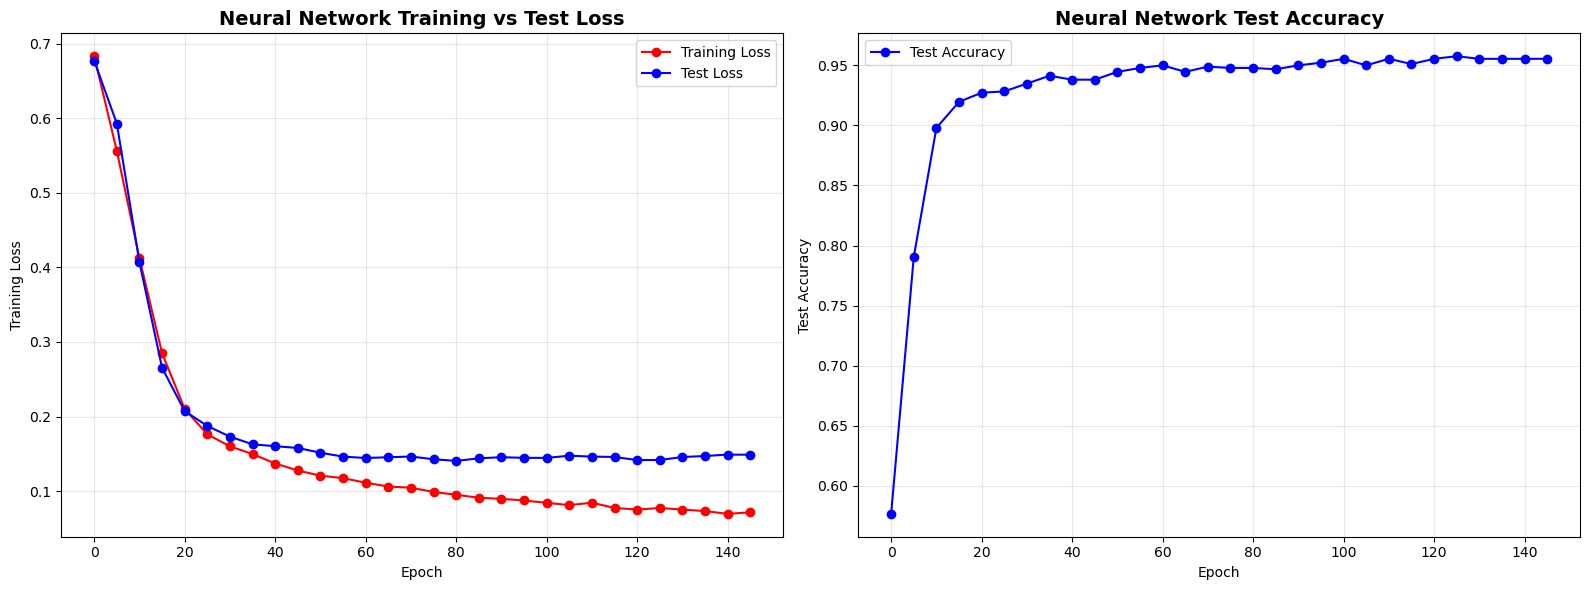

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(epoch_nn, train_loss_nn, label='Training Loss', color='red', marker='o')
axes[0].plot(epoch_nn, test_loss_nn, label='Test Loss', color='blue', marker='o')
axes[0].set_title('Neural Network Training vs Test Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epoch_nn, acc_nn, label='Test Accuracy', color='blue', marker='o')
axes[1].set_title('Neural Network Test Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Test Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Train random forest classifier model

In [37]:
RF_PARAMS = {
    "n_estimators": randint(100, 300),
    "max_depth": randint(3, 12),
    "min_samples_split": randint(2, 10),
    "min_samples_leaf": randint(1, 5),
    #"max_features": "sqrt"
}

rf_model = RandomForestClassifier(**RF_PARAMS, random_state=random_seed)

# tuning hyperparameters
clf = RandomizedSearchCV(rf_model, RF_PARAMS, cv=5, n_iter=10, random_state=random_seed)
clf.fit(X_train, y_train)

print(f"Best Random Forest parameters: {clf.best_params_}")

bestrf_model = RandomForestClassifier(**clf.best_params_, random_state=random_seed)
bestrf_model.fit(X_train, y_train)

acc_rf = bestrf_model.score(X_test, y_test)
precision_rf = precision_score(y_test, bestrf_model.predict(X_test))
recall_rf = recall_score(y_test, bestrf_model.predict(X_test))
print(f"Random Forest accuracy: {acc_rf:.3f}")


Best Random Forest parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 6, 'n_estimators': 202}
Random Forest accuracy: 0.940


In [38]:
log_reg_voter = make_lr_model(best_lr_config)
rf_voter = RandomForestClassifier(**clf.best_params_, random_state=random_seed + 1)
gb_voter = GradientBoostingClassifier(random_state=random_seed)

voting_clf = VotingClassifier(
    estimators=[
        ('lr', log_reg_voter),
        ('rf', rf_voter),
        ('gb', gb_voter)
    ],
    voting='soft',
    weights=[2, 1, 2]
)

voting_clf.fit(X_train, y_train)
acc_voting = voting_clf.score(X_test, y_test)
precision_voting = precision_score(y_test, voting_clf.predict(X_test))
recall_voting = recall_score(y_test, voting_clf.predict(X_test))

print(f"Voting ensemble accuracy: {acc_voting:.3f}")


Voting ensemble accuracy: 0.946


SMOTE implementation

Neural Network accuracy: 0.955 Neural Network (SMOTE) accuracy: 0.954
Random Forest accuracy: 0.940 Random Forest (SMOTE) accuracy: 0.941


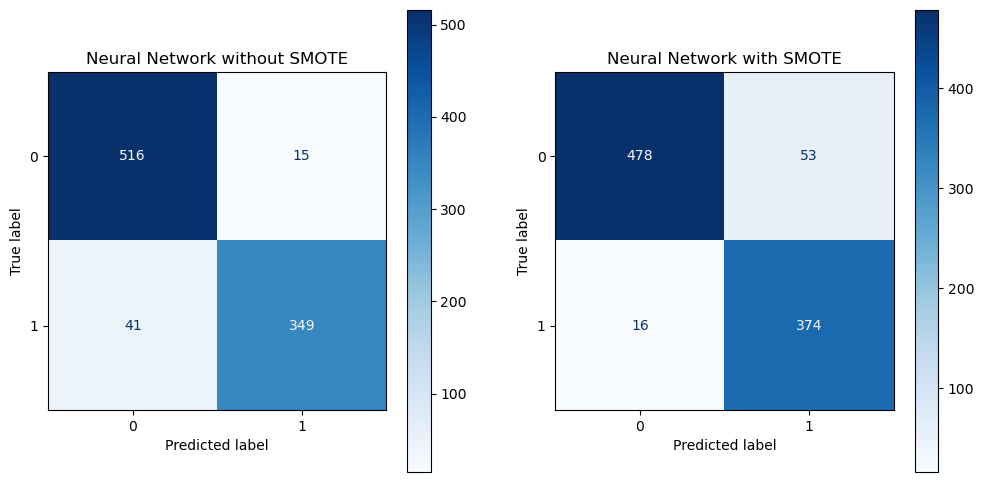

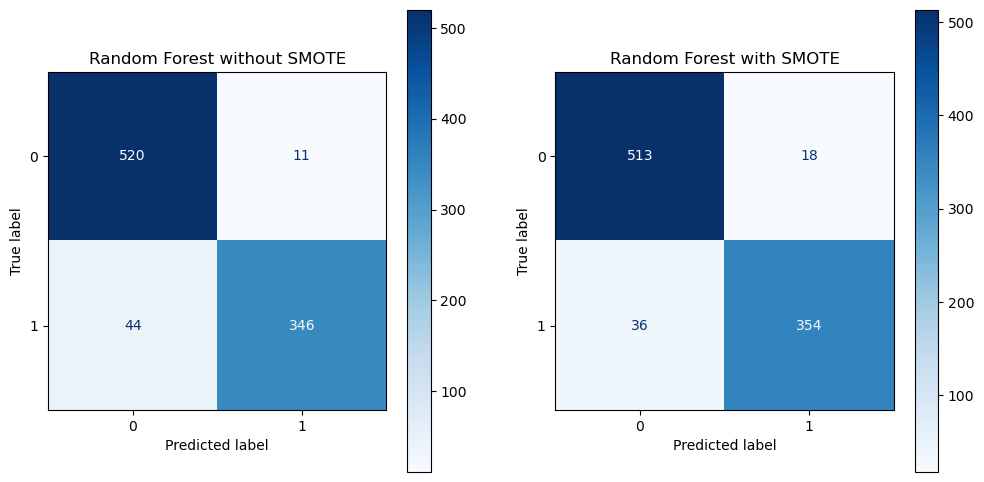

In [39]:
sm = SMOTE(random_state=random_seed)
X_res, y_res = sm.fit_resample(X_train, y_train)

# neural network with resampled data
X_res_t = torch.Tensor(X_res)
y_res_t = torch.Tensor(y_res.to_numpy()).view(-1, 1)

model_nn_smote = NeuralNetwork(n_features, best_dp)
optimizer_nn_smote = optim.Adam(model_nn_smote.parameters(), LR_NN, weight_decay=best_wd)
scheduler_nn_smote = optim.lr_scheduler.StepLR(optimizer_nn_smote, step_size=best_step, gamma=best_gamma)

train_loss_nn_smote, test_loss_nn_smote, acc_nn_smote, recall_nn_smote, precision_nn_smote, epoch_nn_smote = train_neural_network(model_nn_smote, criterion_nn, optimizer_nn_smote, EPOCH_NN, scheduler_nn_smote, X_res_t, y_res_t, X_test_t, y_test_t)

# random forest with resampled data
bestrf_model_smote = RandomForestClassifier(**clf.best_params_, random_state=random_seed)
bestrf_model_smote.fit(X_res, y_res)

# confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

y_pred_nn = model_nn(X_test_t)
cm_nn = confusion_matrix(y_test, (y_pred_nn >= 0.5).int())
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn)
disp.plot(ax=axes[0], cmap=plt.cm.Blues)
axes[0].set_title("Neural Network without SMOTE")

y_pred_nn_smote = model_nn_smote(X_test_t)
cm_nn_smote = confusion_matrix(y_test, (y_pred_nn_smote >= 0.5).int())
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn_smote)
disp.plot(ax=axes[1], cmap=plt.cm.Blues)
axes[1].set_title("Neural Network with SMOTE")

# random forest with resampled data
fig1, axes = plt.subplots(1, 2, figsize=(12, 6))

y_pred_rf = bestrf_model.predict(X_test)
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)
disp.plot(ax=axes[0], cmap=plt.cm.Blues)
axes[0].set_title("Random Forest without SMOTE")

y_pred_rf_smote = bestrf_model_smote.predict(X_test)
cm_rf_smote = confusion_matrix(y_test, y_pred_rf_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote)
disp.plot(ax=axes[1], cmap=plt.cm.Blues)
axes[1].set_title("Random Forest with SMOTE")

# accuracies
acc_nn_smote = acc_nn_smote[-1]
print(f"Neural Network accuracy: {acc_nn[-1]:.3f} Neural Network (SMOTE) accuracy: {acc_nn_smote:.3f}")
acc_rf_smote = bestrf_model_smote.score(X_test, y_test)
precision_rf_smote = precision_score(y_test, bestrf_model_smote.predict(X_test))
recall_rf_smote = recall_score(y_test, bestrf_model_smote.predict(X_test))
print(f"Random Forest accuracy: {acc_rf:.3f} Random Forest (SMOTE) accuracy: {acc_rf_smote:.3f}")
# undersampling majority?



Final Results: Compare model accuracy with baseline majority vote performance

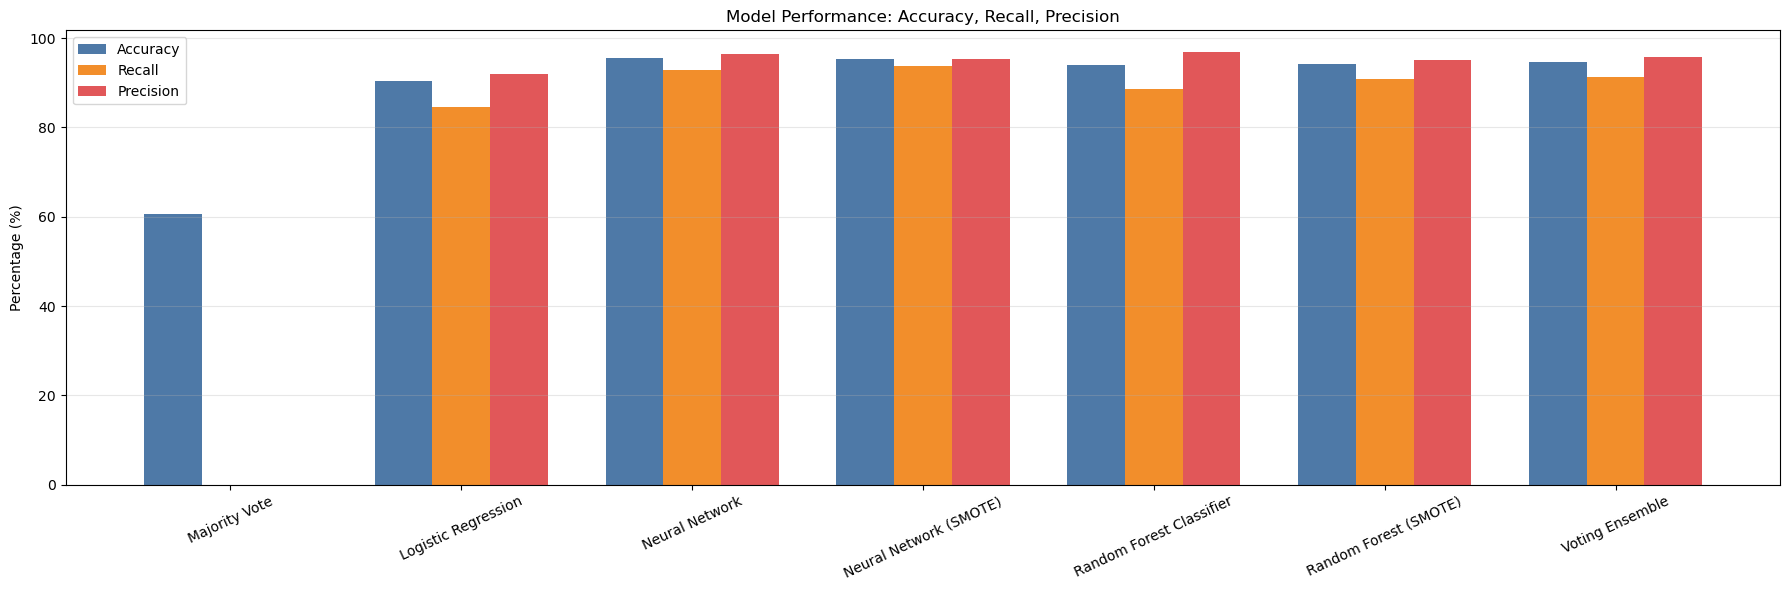

In [40]:
models = ['Majority Vote', 'Logistic Regression', 'Neural Network', 'Neural Network (SMOTE)',
          'Random Forest Classifier', 'Random Forest (SMOTE)', 'Voting Ensemble']

accuracy = [baseline_accuracy*100, acc_lr[-1]*100, acc_nn[-1]*100, acc_nn_smote*100, acc_rf*100, acc_rf_smote*100, acc_voting*100]
recall = [0, recall_lr[-1]*100, recall_nn[-1]*100, recall_nn_smote[-1]*100, recall_rf*100, recall_rf_smote*100, recall_voting*100]
precision = [0, precision_lr[-1]*100, precision_nn[-1]*100, precision_nn_smote[-1]*100, precision_rf*100, precision_rf_smote*100, precision_voting*100]

x = np.arange(len(models))  # the label locations
width = 0.25                # width of each bar

plt.figure(figsize=(18, 6))

# Plot each metric as a separate bar
plt.bar(x - width, accuracy, width, label='Accuracy', color='#4E79A7')
plt.bar(x, recall, width, label='Recall', color='#F28E2B')
plt.bar(x + width, precision, width, label='Precision', color='#E15759')

# Labels and title
plt.xticks(x, models, rotation=25)
plt.ylabel('Percentage (%)')
plt.title('Model Performance: Accuracy, Recall, Precision')
plt.grid(True, axis='y', alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [41]:
# stratified 5-fold splits
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)

# define each model, evaluate with cross-validation
cv_models = {
    'Logistic Regression (tuned)': make_pipeline(StandardScaler(), make_lr_model(best_lr_config)),
    'Random Forest': RandomForestClassifier(**clf.best_params_, random_state=random_seed),
    'Voting Ensemble': make_pipeline(
        StandardScaler(),
        VotingClassifier(
            estimators=[
                ('lr', make_lr_model(best_lr_config)),
                ('rf', RandomForestClassifier(**clf.best_params_, random_state=random_seed + 3)),
                ('gb', GradientBoostingClassifier(random_state=random_seed + 4))
            ],
            voting='soft',
            weights=[2, 1, 2]
        )
    )
}

cv_results = {}

for name, estimator in cv_models.items():
    scores = cross_val_score(estimator, X, y, cv=skf, scoring='accuracy')
    cv_results[name] = scores
    print(f"{name}: mean accuracy={scores.mean():.3f}, std={scores.std():.3f}")


Logistic Regression (tuned): mean accuracy=0.925, std=0.007
Random Forest: mean accuracy=0.942, std=0.005
Voting Ensemble: mean accuracy=0.945, std=0.004
